<a href="https://colab.research.google.com/github/JohanImbolBioDev/Arboles-ultrametricos-y-datacion-molecular/blob/main/Taller1_Ultrametricos_Datacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller 1 · Árboles ultramétricos y datación molecular
**Biogeografía · Pregrado en Biología**

Duración: **2 h 30 min** · Lenguaje: **R** · Entorno: **Google Colab**

---

### Objetivos de aprendizaje
Al terminar este taller podrás:

1. Distinguir un **filograma** (largos de rama = sustituciones) de un **cronograma** (largos de rama = tiempo) y reconocer cuándo un árbol es **ultramétrico**.
2. Explicar por qué un árbol con linajes extintos no es ultramétrico y qué muestra una curva **LTT**.
3. Evaluar la hipótesis de **reloj molecular estricto** con una prueba de razón de verosimilitudes.
4. **Datar un árbol** con verosimilitud penalizada (`chronos`) usando calibraciones y valorar el efecto del modelo de reloj, del parámetro de suavizado λ y de las calibraciones.
5. Reconocer que **las edades estimadas son hipótesis con incertidumbre**.

### La gran ventaja de este taller: trabajamos con datos simulados
En la vida real nunca conocemos las edades verdaderas de los nodos. Aquí **simulamos** la historia (el árbol en tiempo y las secuencias de ADN), así que podemos comparar lo que estiman los métodos con **la verdad**. Es la forma más honesta de entender qué hacen bien y qué hacen mal.

### Agenda sugerida
| Bloque | Tema | Tiempo |
|---|---|---|
| 0 | Preparar el entorno | 10 min |
| 1 | Árboles ultramétricos, extinción y LTT | 35 min |
| 2 | El reloj molecular: ¿se cumple? | 35 min |
| ☕ | Pausa | 10 min |
| 3 | Datación con verosimilitud penalizada (`chronos`) | 40 min |
| 4 | Incertidumbre en las calibraciones | 15 min |
| 5 | Cierre y preguntas para entregar | 5 min |

### Cómo usar este cuaderno
- Ejecuta las celdas **en orden** con `Shift + Enter`.
- Las celdas marcadas con ✍️ son **preguntas**: responde en la celda de texto que sigue (doble clic para editar).
- Las celdas 🧪 son **actividades**: modifica el código y vuelve a ejecutar.
- Si algo falla: *Entorno de ejecución → Reiniciar sesión* y vuelve a ejecutar desde el bloque 0.
- Guarda tu copia: *Archivo → Guardar una copia en Drive*.

## Bloque 0 · Preparar el entorno (≈10 min)

Comprueba que el cuaderno usa **R**: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → R*.

La siguiente celda instala los paquetes `ape`, `phytools` y `phangorn`. Usamos un repositorio con versiones **precompiladas** para Linux, así la instalación tarda 2–4 minutos en lugar de 15. **Ejecútala ya** y mientras tanto lee la introducción del bloque 1.

In [ ]:
# Instalación de paquetes (solo hace falta una vez por sesión de Colab)
codename <- if (file.exists("/etc/os-release")) {
  sub("VERSION_CODENAME=", "", grep("^VERSION_CODENAME=", readLines("/etc/os-release"), value = TRUE))
} else ""
if (length(codename) == 1 && nzchar(codename) && Sys.info()[["sysname"]] == "Linux") {
  # Binarios precompilados de Posit Package Manager (mucho más rápido en Colab)
  options(repos = c(CRAN = paste0("https://packagemanager.posit.co/cran/__linux__/", codename, "/latest")),
          HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(),
                                  paste(getRversion(), R.version$platform, R.version$arch, R.version$os)))
} else {
  options(repos = c(CRAN = "https://cloud.r-project.org"))
}

# Bibliotecas de sistema que necesitan algunos binarios (igraph, del que depende phytools, usa GLPK)
if (Sys.info()[["sysname"]] == "Linux" && system("ldconfig -p | grep -q libglpk.so.40") != 0) {
  system("apt-get -qq install -y libglpk40 > /dev/null 2>&1 || (apt-get -qq update > /dev/null && apt-get -qq install -y libglpk40 > /dev/null)")
}

paquetes <- c("ape", "phytools", "phangorn")
faltan <- paquetes[!paquetes %in% rownames(installed.packages())]
if (length(faltan) > 0) install.packages(faltan)

suppressPackageStartupMessages({
  library(ape)
  library(phytools)
  library(phangorn)
})

# Tamaño por defecto de las figuras en Colab
tam <- function(ancho = 10, alto = 6) options(repr.plot.width = ancho, repr.plot.height = alto)
tam()
cat("✅ Listo. ape", as.character(packageVersion("ape")),
    "| phytools", as.character(packageVersion("phytools")),
    "| phangorn", as.character(packageVersion("phangorn")), "\n")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘iterators’, ‘maps’, ‘clusterGeneration’, ‘coda’, ‘combinat’, ‘DEoptim’, ‘doParallel’, ‘expm’, ‘foreach’, ‘mnormt’, ‘numDeriv’, ‘optimParallel’, ‘scatterplot3d’, ‘fastmatch’, ‘igraph’, ‘quadprog’




✅ Listo. ape 5.8.1 | phytools 2.5.2 | phangorn 2.12.1 


## Bloque 1 · Árboles ultramétricos (≈35 min)

### 1.1 ¿Qué significa "ultramétrico"?
Un árbol es **ultramétrico** cuando **todas las puntas están a la misma distancia de la raíz**. Esto ocurre de forma natural cuando:

- los largos de rama representan **tiempo**, y
- todas las puntas son **contemporáneas** (especies vivas muestreadas hoy).

A este tipo de árbol lo llamamos **cronograma**. En cambio, un árbol estimado a partir de secuencias tiene ramas en **sustituciones por sitio** (un **filograma**). Como cada linaje evoluciona a su propia velocidad, los filogramas casi nunca son ultramétricos.

Empecemos simulando un clado de 20 especies vivas que se originó hace 10 millones de años (Ma), con un modelo de nacimiento y muerte (especiación `b`, extinción `d`).

¿Árbol completo ultramétrico? FALSE 
¿Árbol de vivos ultramétrico? TRUE 


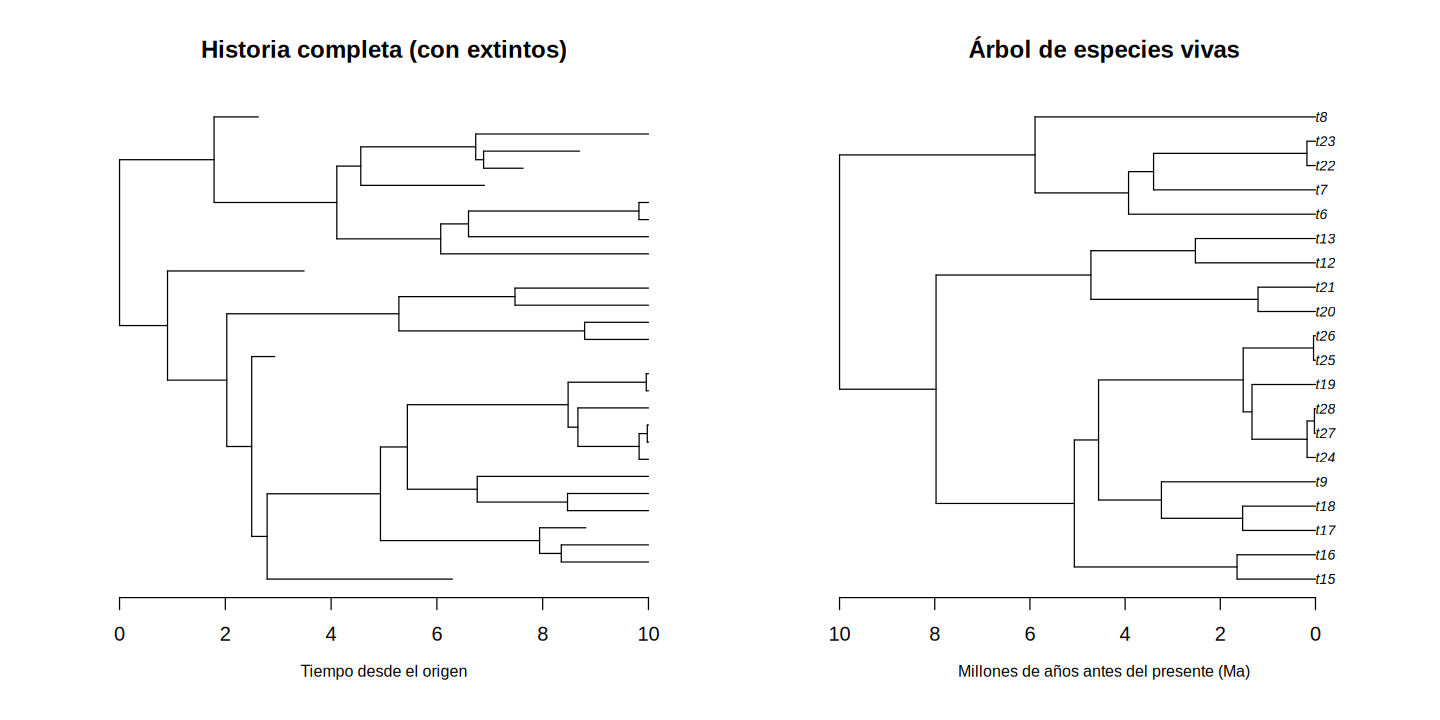

In [ ]:
set.seed(2024)   # semilla: hace que todos obtengamos el mismo resultado

# Árbol completo: incluye linajes que se extinguieron
arbol_completo <- pbtree(b = 1, d = 0.4, n = 20, extant.only = FALSE)

# Árbol "reconstruido": solo los linajes que sobreviven hasta hoy
arbol_vivos <- drop.tip(arbol_completo, getExtinct(arbol_completo))

# Escalamos para que la raíz tenga 10 Ma
escala <- 10 / max(nodeHeights(arbol_vivos))
arbol_vivos$edge.length <- arbol_vivos$edge.length * escala
arbol_completo$edge.length <- arbol_completo$edge.length * escala

tam(12, 6)
par(mfrow = c(1, 2))
plot(arbol_completo, show.tip.label = FALSE, main = "Historia completa (con extintos)")
axisPhylo(backward = FALSE); mtext("Tiempo desde el origen", side = 1, line = 2.5, cex = 0.8)
plot(arbol_vivos, cex = 0.7, main = "Árbol de especies vivas")
axisPhylo(); mtext("Millones de años antes del presente (Ma)", side = 1, line = 2.5, cex = 0.8)
par(mfrow = c(1, 1))

cat("¿Árbol completo ultramétrico?", is.ultrametric(arbol_completo), "\n")
cat("¿Árbol de vivos ultramétrico?", is.ultrametric(arbol_vivos), "\n")

La función `is.ultrametric()` responde `TRUE`/`FALSE`. Veámoslo con números: calculamos la **distancia raíz–punta** de cada especie.

In [ ]:
dist_raiz <- function(arbol) {
  d <- node.depth.edgelength(arbol)[1:Ntip(arbol)]
  names(d) <- arbol$tip.label
  d
}
cat("arbol de especies vivas\n")
d_vivos <- dist_raiz(arbol_vivos)
print.table(round(d_vivos, 3))

cat("\nRango de distancias raíz-punta:", round(range(d_vivos), 3), "Ma\n")

arbol de especies vivas
t15 t16 t17 t18  t9 t24 t27 t28 t19 t25 t26 t20 t21 t12 t13  t6  t7 t22 t23  t8 
 10  10  10  10  10  10  10  10  10  10  10  10  10  10  10  10  10  10  10  10 

Rango de distancias raíz-punta: 10 10 Ma


In [ ]:
cat("Historia completa (con extintos)\n")
d_completo <- dist_raiz(arbol_completo)
print.table(round(d_completo, 0))

cat("\nRango de distancias raíz-punta:", round(range(d_completo), 3), "Ma\n")

Historia completa (con extintos)
 t4 t15 t16 t14 t17 t18  t9 t24 t27 t28 t19 t25 t26  t3 t20 t21 t12 t13  t1  t6 
  6  10  10   9  10  10  10  10  10  10  10  10  10   3  10  10  10  10   3  10 
 t7 t22 t23  t5 t10 t11  t8  t2 
 10  10  10   7   8   9  10   3 

Rango de distancias raíz-punta: 2.623 10 Ma


✍️ **Pregunta 1.1.** ¿Por qué el árbol que incluye los linajes extintos **no** es ultramétrico? ¿Qué tipo de datos (piensa en el registro fósil) producen árboles no ultramétricos aun cuando las ramas están en tiempo?

*Tu respuesta aquí.*

### 1.2 Filograma vs. cronograma
Ahora "hacemos evolucionar" secuencias sobre este árbol. La cantidad de cambio en una rama es **tasa × tiempo**. Si cada rama tiene su propia tasa (reloj **relajado**), el árbol en sustituciones deja de ser ultramétrico.

Usaremos una tasa media de 0.01 sustituciones/sitio/Ma (≈ la famosa "regla del 2 % por millón de años" para ADN mitocondrial, que es una divergencia **por pares**: 1 % por linaje).

In [ ]:
set.seed(7)
tasa_media <- 0.01   # sustituciones / sitio / Ma
sd_tasas   <- 0.5    # variación de tasas entre ramas (0 = reloj estricto)

tasas <- rlnorm(Nedge(arbol_vivos), meanlog = log(tasa_media), sdlog = sd_tasas)
filograma <- arbol_vivos
filograma$edge.length <- arbol_vivos$edge.length * tasas

tam(12, 6)
par(mfrow = c(1, 2))
plot(arbol_vivos, cex = 0.7, main = "Cronograma (tiempo)")
axisPhylo()
plot(filograma, cex = 0.7, main = "Filograma (sustituciones/sitio)")
add.scale.bar()
par(mfrow = c(1, 1))

cat("¿Filograma ultramétrico?", is.ultrametric(filograma), "\n")

In [ ]:
# Distancias raíz-punta en ambos árboles
tam(10, 5)
par(mfrow = c(1, 2))
barplot(sort(dist_raiz(arbol_vivos)), las = 2, cex.names = 0.6, col = "steelblue",
        main = "Cronograma", ylab = "Distancia raíz-punta (Ma)")
barplot(sort(dist_raiz(filograma)), las = 2, cex.names = 0.6, col = "tomato",
        main = "Filograma", ylab = "Distancia raíz-punta (sust./sitio)")
par(mfrow = c(1, 1))

🧪 **Actividad 1.2.** En la celda donde se simulan las tasas, cambia `sd_tasas` a `0` y vuelve a ejecutar esa celda y la siguiente.

- ¿Qué pasa con el filograma? ¿Es ultramétrico?
- ¿Qué supuesto biológico estás haciendo cuando `sd_tasas = 0`?
- Prueba con `sd_tasas = 1`. ¿Qué linajes quedan más "largos"?

Al terminar, **vuelve a dejar `sd_tasas <- 0.5`** y ejecuta de nuevo las dos celdas.

*Tu respuesta aquí.*

### 1.3 Un problema práctico: árboles "casi" ultramétricos
Muchas veces descargamos un cronograma (por ejemplo, de TimeTree o de un artículo) y `is.ultrametric()` dice `FALSE`. Casi siempre es un problema de **redondeo** de decimales en el archivo Newick.

In [ ]:
# Simulamos el problema: redondeamos los largos de rama a 2 decimales
arbol_redondeado <- arbol_vivos
arbol_redondeado$edge.length <- round(arbol_redondeado$edge.length, 2)
write.tree(arbol_redondeado, "arbol_redondeado.tre")
arbol_leido <- read.tree("arbol_redondeado.tre")

cat("¿Ultramétrico tras redondear?", is.ultrametric(arbol_leido), "\n")
cat("Diferencia máxima entre distancias raíz-punta:",
    round(diff(range(dist_raiz(arbol_leido))), 4), "Ma\n")

# Solución correcta para errores de redondeo pequeños:
arbol_corregido <- force.ultrametric(arbol_leido, method = "extend")
cat("¿Ultramétrico tras force.ultrametric?", is.ultrametric(arbol_corregido), "\n")

⚠️ **¡Cuidado!** `force.ultrametric()` sirve para corregir **errores numéricos minúsculos**. **No** es un método de datación. Mira lo que pasa si lo aplicamos a un filograma con tasas variables: comparamos las edades de los nodos que "inventa" con las edades verdaderas.

In [ ]:
falso_cronograma <- force.ultrametric(filograma, method = "nnls")
# Re-escalamos para que la raíz tenga la edad verdadera (10 Ma)
falso_cronograma$edge.length <- falso_cronograma$edge.length * 10 / max(nodeHeights(falso_cronograma))

edad_verdadera <- branching.times(arbol_vivos)
edad_falsa     <- branching.times(falso_cronograma)

tam(6, 6)
plot(edad_verdadera, edad_falsa, pch = 19, col = "tomato",
     xlab = "Edad verdadera del nodo (Ma)", ylab = "Edad con force.ultrametric (Ma)",
     main = "force.ultrametric NO es datación", xlim = c(0, 10), ylim = c(0, 10))
abline(0, 1, lty = 2)

### 1.4 Curvas de linajes a través del tiempo (LTT)
Una aplicación directa de los cronogramas: contar cuántos linajes existen en cada momento. La curva **LTT** (*lineages-through-time*) en escala logarítmica es una recta si la diversificación es constante y no hay extinción. Con extinción, la curva del árbol reconstruido se "levanta" cerca del presente (**pull of the present**), porque los linajes recientes aún no han tenido tiempo de extinguirse.

In [ ]:
tam(8, 6)
ltt_completo <- ltt(arbol_completo, plot = FALSE)
ltt_vivos    <- ltt(arbol_vivos, plot = FALSE)
# Pasamos los tiempos a "millones de años antes del presente"
presente_completo <- max(nodeHeights(arbol_completo))
presente_vivos    <- max(nodeHeights(arbol_vivos))
plot(presente_completo - ltt_completo$times, ltt_completo$ltt, type = "s", log = "y",
     col = "grey50", lwd = 2, xlim = rev(range(presente_completo - ltt_completo$times)),
     main = "Linajes a través del tiempo", xlab = "Millones de años antes del presente",
     ylab = "Número de linajes (escala log)")
lines(presente_vivos - ltt_vivos$times, ltt_vivos$ltt, type = "s", col = "steelblue", lwd = 3)
legend("topleft", c("Historia completa (con extintos)", "Árbol reconstruido (vivos)"),
       col = c("grey50", "steelblue"), lwd = 2, bty = "n")

cat("Estadístico gamma de Pybus & Harvey:", round(ltt_vivos$gamma, 3),
    "  (p =", round(ltt_vivos$p, 3), ")\n")

El estadístico **γ (gamma)** resume la forma de la curva: γ < 0 indica que los nodos se concentran cerca de la raíz (desaceleración de la diversificación, típico de radiaciones adaptativas); γ > 0 indica nodos concentrados cerca del presente.

✍️ **Pregunta 1.4.** ¿Por qué necesitamos un árbol **ultramétrico (en tiempo)** para construir una curva LTT o hacer cualquier inferencia biogeográfica que involucre fechas (p. ej., "¿este clado se diversificó después del levantamiento de los Andes?")?

*Tu respuesta aquí.*

## Bloque 2 · El reloj molecular: ¿se cumple? (≈35 min)

Hipótesis del **reloj molecular** (Zuckerkandl & Pauling, 1965): las secuencias acumulan sustituciones a una tasa aproximadamente constante. Si fuera cierto, las distancias genéticas serían proporcionales al tiempo y datar sería trivial.

Vamos a simular **dos conjuntos de secuencias de ADN** (1500 pb) sobre el mismo árbol de 15 especies con raíz de 20 Ma:

- **A:** con **reloj estricto** (misma tasa en todas las ramas).
- **B:** con **reloj relajado** (cada rama tiene su propia tasa).

Y luego preguntaremos a los datos si el reloj se cumple.

In [ ]:
set.seed(42)
n_sp <- 15
arbol_real <- pbtree(n = n_sp, scale = 20,
                     tip.label = paste0("sp", sprintf("%02d", 1:n_sp)))  # cronograma verdadero, raíz = 20 Ma

tasa <- 0.008                                         # sust./sitio/Ma
filo_estricto <- arbol_real
filo_estricto$edge.length <- arbol_real$edge.length * tasa

set.seed(43)
filo_relajado <- arbol_real
filo_relajado$edge.length <- arbol_real$edge.length *
  rlnorm(Nedge(arbol_real), log(tasa), sdlog = 0.6)

set.seed(44)
secs_estricto <- simSeq(filo_estricto, l = 1500, type = "DNA")   # modelo JC69
secs_relajado <- simSeq(filo_relajado, l = 1500, type = "DNA")

secs_relajado
tam(10, 6)
plot(arbol_real, main = "Árbol verdadero (¡en la vida real no lo conocemos!)", cex = 0.8)
axisPhylo(); nodelabels(round(branching.times(arbol_real), 1), frame = "none", adj = c(1.1, -0.4), cex = 0.7, col = "darkred")

### 2.1 Una primera mirada: la "regla del 2 %"
Si el reloj se cumpliera, podríamos datar una divergencia directamente:

$$ t = \frac{d}{2r} $$

donde *d* es la distancia genética entre dos especies (sustituciones/sitio) y *r* la tasa por linaje. El factor 2 aparece porque **ambos** linajes acumulan cambios desde el ancestro común.

In [ ]:
d_estricto <- dist.dna(as.DNAbin(secs_estricto), model = "JC69")
d_relajado <- dist.dna(as.DNAbin(secs_relajado), model = "JC69")

# Edad verdadera de cada par = la mitad de la distancia patrística en el cronograma
t_real <- as.dist(cophenetic(arbol_real) / 2)

tam(12, 5)
par(mfrow = c(1, 2))
plot(t_real, d_estricto / (2 * tasa), pch = 19, col = adjustcolor("steelblue", 0.5),
     xlab = "Edad verdadera de la divergencia (Ma)", ylab = "Edad estimada  t = d / 2r",
     main = "Reloj estricto")
abline(0, 1, lty = 2)
plot(t_real, d_relajado / (2 * tasa), pch = 19, col = adjustcolor("tomato", 0.5),
     xlab = "Edad verdadera de la divergencia (Ma)", ylab = "Edad estimada  t = d / 2r",
     main = "Reloj relajado")
abline(0, 1, lty = 2)
par(mfrow = c(1, 1))

✍️ **Pregunta 2.1.**
a) Compara los dos paneles. ¿Por qué con reloj relajado los puntos se dispersan tanto alrededor de la línea 1:1?
b) 🧪 En la celda anterior cambia `model = "JC69"` por `model = "raw"` (distancia *p*: proporción de sitios distintos, **sin** corregir por sustituciones múltiples) en las dos líneas de `dist.dna` y vuelve a ejecutar. ¿Qué pasa con las divergencias más antiguas? ¿Por qué? *Pista: saturación.*
c) ¿Qué pasaría con todas las edades si la tasa usada (*r*) estuviera mal, p. ej., si la tomáramos de otro grupo taxonómico que evoluciona el doble de rápido?

*Tu respuesta aquí.*

### 2.2 Prueba de razón de verosimilitudes (LRT) del reloj molecular
Ajustamos dos modelos por **máxima verosimilitud** sobre la misma topología:

- **Sin reloj**: cada una de las 2n − 3 ramas tiene su propio largo (árbol no enraizado).
- **Con reloj**: el árbol está enraizado y es ultramétrico; solo se estiman las n − 1 edades de los nodos.

El modelo con reloj está **anidado** dentro del modelo sin reloj, así que podemos compararlos:

$$ LRT = 2(\ln L_{sin\ reloj} - \ln L_{reloj}) \sim \chi^2_{\,gl = n-2} $$

> Para simplificar usamos la topología verdadera. En un estudio real, primero se estima la topología (p. ej., con IQ-TREE o RAxML).

In [ ]:
prueba_reloj <- function(secs, arbol_top) {
  # Modelo SIN reloj: árbol no enraizado, todas las ramas libres
  inicio <- unroot(arbol_top)
  inicio$edge.length <- rep(0.01, Nedge(inicio))
  sin_reloj <- optim.pml(pml(inicio, secs), optEdge = TRUE, control = pml.control(trace = 0))

  # Modelo CON reloj: árbol enraizado y ultramétrico
  inicio_r <- arbol_top
  inicio_r$edge.length <- inicio_r$edge.length / max(nodeHeights(inicio_r)) * 0.1
  con_reloj <- optim.pml(pml(inicio_r, secs), optRooted = TRUE, control = pml.control(trace = 0))

  lrt <- 2 * (sin_reloj$logLik - con_reloj$logLik)
  gl  <- Ntip(arbol_top) - 2
  data.frame(lnL_sin_reloj = round(sin_reloj$logLik, 2),
             lnL_con_reloj = round(con_reloj$logLik, 2),
             LRT = round(lrt, 2), gl = gl,
             valor_p = signif(pchisq(lrt, df = gl, lower.tail = FALSE), 3))
}

resultado_lrt <- rbind(
  "A: reloj estricto" = prueba_reloj(secs_estricto, arbol_real),
  "B: reloj relajado" = prueba_reloj(secs_relajado, arbol_real))
resultado_lrt

✍️ **Pregunta 2.2.** Interpreta los dos valores *p*. ¿En qué conjunto de datos se rechaza el reloj estricto? ¿Qué esperas que ocurra con el poder de la prueba si las secuencias fueran mucho más cortas (p. ej., 200 pb)? Si tienes tiempo, compruébalo cambiando `l = 1500` por `l = 200` en `simSeq`.

*Tu respuesta aquí.*

### 2.3 Estimamos el filograma por máxima verosimilitud
Para los bloques siguientes necesitamos el árbol estimado a partir de las secuencias del **reloj relajado** (el caso realista). Lo enraizamos usando el nodo raíz verdadero (en la práctica usaríamos un **grupo externo**).

In [ ]:
inicio <- unroot(arbol_real); inicio$edge.length <- rep(0.01, Nedge(inicio))
ml_relajado <- optim.pml(pml(inicio, secs_relajado), optEdge = TRUE,
                         control = pml.control(trace = 0))

# Enraizar con los descendientes de uno de los hijos de la raíz verdadera
hijo <- Children(arbol_real, Ntip(arbol_real) + 1)[1]
externo <- if (hijo <= Ntip(arbol_real)) arbol_real$tip.label[hijo] else extract.clade(arbol_real, hijo)$tip.label
filograma_ml <- root(ml_relajado$tree, outgroup = externo, resolve.root = TRUE)

# Repartimos el largo de la rama raíz en partes iguales
ramas_raiz <- which(filograma_ml$edge[, 1] == Ntip(filograma_ml) + 1)
filograma_ml$edge.length[ramas_raiz] <- sum(filograma_ml$edge.length[ramas_raiz]) / 2

tam(10, 6)
plot(filograma_ml, cex = 0.8, main = "Filograma ML (datos con reloj relajado)")
add.scale.bar()
cat("Coeficiente de variación de las distancias raíz-punta:",
    round(sd(dist_raiz(filograma_ml)) / mean(dist_raiz(filograma_ml)), 3), "\n")

## ☕ Pausa (10 min)

---

## Bloque 3 · Datación con verosimilitud penalizada (≈40 min)

Si el reloj no se cumple, necesitamos métodos que **permitan que la tasa cambie entre ramas** y que usen **calibraciones** (fósiles, eventos geológicos, edades secundarias) para convertir sustituciones en tiempo.

La función `chronos()` de `ape` implementa la **verosimilitud penalizada** (Sanderson 2002; Paradis 2013). Busca las edades de los nodos y las tasas de cada rama que maximizan:

$$ \ln L(\text{tasas, edades}) \; - \; \lambda \times \text{penalización por cambios de tasa} $$

- **λ pequeño** → las tasas pueden variar mucho (casi sin reloj).
- **λ grande** → se castiga la variación de tasas (se acerca al reloj estricto).

Modelos disponibles en `chronos`: `"clock"` (estricto), `"correlated"` (tasas de ramas vecinas parecidas), `"relaxed"` (tasas independientes), `"discrete"` (k categorías de tasas).

### 3.1 Calibraciones
Supongamos que tenemos dos fuentes de información independientes:

1. Un **fósil** que pertenece al clado más antiguo dentro de nuestro grupo → edad mínima de ese nodo.
2. Un **evento geológico** (p. ej., la formación de una cordillera) que acota la edad de la raíz entre 18 y 22 Ma.

In [ ]:
raiz <- Ntip(filograma_ml) + 1

# Elegimos como "nodo con fósil" el nodo interno más antiguo después de la raíz
edades_real <- branching.times(arbol_real)
nodo_fosil_real <- as.numeric(names(sort(edades_real, decreasing = TRUE))[2])
taxones_fosil <- extract.clade(arbol_real, nodo_fosil_real)$tip.label
nodo_fosil <- getMRCA(filograma_ml, taxones_fosil)   # mismo clado en el árbol estimado

cat("Edad verdadera de la raíz:", round(edades_real[as.character(Ntip(arbol_real) + 1)], 2), "Ma\n")
cat("Edad verdadera del nodo con fósil:", round(edades_real[as.character(nodo_fosil_real)], 2), "Ma\n")
cat("Clado calibrado con el fósil:", paste(taxones_fosil, collapse = ", "), "\n")

calibracion <- rbind(
  makeChronosCalib(filograma_ml, node = raiz,       age.min = 18, age.max = 22),
  makeChronosCalib(filograma_ml, node = nodo_fosil, age.min = 14, age.max = 22))
calibracion

### 3.2 Nuestra primera datación

In [ ]:
crono_cor <- chronos(filograma_ml, lambda = 1, model = "correlated",
                     calibration = calibracion, quiet = TRUE)

tam(12, 6)
par(mfrow = c(1, 2))
plot(arbol_real, cex = 0.75, main = "Cronograma VERDADERO"); axisPhylo()
plot(crono_cor, cex = 0.75, main = "Cronograma ESTIMADO (chronos, correlated)"); axisPhylo()
par(mfrow = c(1, 1))

> 💬 Si aparece la advertencia `false convergence (8)`, no te alarmes: indica que el optimizador se detuvo antes de cumplir su criterio más estricto. Es frecuente en `chronos`; en un análisis real conviene repetir con otros valores iniciales o con otro λ y comprobar que las edades no cambian mucho. En el resto del cuaderno silenciamos estas advertencias con `suppressWarnings()`.

Para comparar nodo a nodo, buscamos en el árbol verdadero el nodo que contiene **exactamente las mismas especies**:

In [ ]:
comparar_edades <- function(estimado, verdadero) {
  nodos <- (Ntip(estimado) + 1):(Ntip(estimado) + estimado$Nnode)
  be <- branching.times(estimado)
  bv <- branching.times(verdadero)
  v  <- sapply(nodos, function(n) {
    taxa <- if (n == Ntip(estimado) + 1) estimado$tip.label else extract.clade(estimado, n)$tip.label
    bv[as.character(getMRCA(verdadero, taxa))]
  })
  data.frame(nodo = nodos, verdadera = as.numeric(v), estimada = as.numeric(be[as.character(nodos)]))
}

tabla <- comparar_edades(crono_cor, arbol_real)
tabla$error <- tabla$estimada - tabla$verdadera
print(round(tabla, 2))
cat("\nError absoluto medio:", round(mean(abs(tabla$error)), 2), "Ma\n")

tam(6, 6)
plot(tabla$verdadera, tabla$estimada, pch = 19, col = "darkorange", xlim = c(0, 22), ylim = c(0, 22),
     xlab = "Edad verdadera (Ma)", ylab = "Edad estimada (Ma)", main = "chronos · correlated · λ = 1")
abline(0, 1, lty = 2)

### 3.3 ¿Qué modelo de reloj y qué λ?
`chronos` devuelve un criterio de información, el **PHIIC** (*penalized-likelihood information criterion*): **menor es mejor**, de forma análoga al AIC. Probemos varias combinaciones.

In [ ]:
modelos <- c("clock", "correlated", "relaxed")
lambdas <- c(0.01, 1, 100)

resultados <- data.frame()
cronos <- list()
for (m in modelos) {
  for (l in lambdas) {
    if (m == "clock" && l != 1) next          # lambda no afecta al reloj estricto
    cr <- suppressWarnings(chronos(filograma_ml, lambda = l, model = m, calibration = calibracion, quiet = TRUE))
    cronos[[paste(m, l)]] <- cr
    tb <- comparar_edades(cr, arbol_real)
    resultados <- rbind(resultados, data.frame(
      modelo = m, lambda = l,
      PHIIC = round(attr(cr, "PHIIC")$PHIIC, 2),
      error_medio_Ma = round(mean(abs(tb$estimada - tb$verdadera)), 2)))
  }
}
resultados[order(resultados$PHIIC), ]

In [ ]:
tam(12, 4.5)
par(mfrow = c(1, 3))
for (nm in c("clock 1", "correlated 1", "relaxed 1")) {
  tb <- comparar_edades(cronos[[nm]], arbol_real)
  plot(tb$verdadera, tb$estimada, pch = 19, col = "darkorange", xlim = c(0, 22), ylim = c(0, 22),
       xlab = "Edad verdadera (Ma)", ylab = "Edad estimada (Ma)", main = nm)
  abline(0, 1, lty = 2)
}
par(mfrow = c(1, 1))

✍️ **Pregunta 3.3.**
a) ¿Qué modelo seleccionarías según el PHIIC? Recuerda que los datos se simularon con un reloj **relajado**: ¿te sorprende el resultado?
b) Compara el ranking por PHIIC con la columna `error_medio_Ma`. ¿Coinciden? ¿Cómo es posible que un modelo "equivocado" dé edades razonables? *Pista: ¿cuánta información aportan las calibraciones?*
c) En un estudio real **no** podemos calcular `error_medio_Ma`. ¿Qué nos dice esto sobre la confianza que debemos tener en la selección de modelos de reloj?

*Tu respuesta aquí.*

### 3.4 🧪 Actividad: el poder (y el peligro) de las calibraciones
Modifica la calibración y observa cómo cambian las edades. Prueba **al menos dos** escenarios:

1. **Solo la raíz** calibrada (elimina el fósil).
2. **Calibración equivocada**: un paleontólogo asignó mal el fósil y la edad mínima es `5` Ma en lugar de `14`.
3. **Raíz mal calibrada**: la raíz entre `30` y `35` Ma.

¿Qué escenario produce los peores errores? ¿Qué te enseña esto sobre cómo elegir calibraciones?

In [ ]:
# ✏️ Modifica aquí
mi_calibracion <- rbind(
  makeChronosCalib(filograma_ml, node = raiz,       age.min = 18, age.max = 22),
  makeChronosCalib(filograma_ml, node = nodo_fosil, age.min = 14, age.max = 22))

mi_crono <- chronos(filograma_ml, lambda = 1, model = "correlated",
                    calibration = mi_calibracion, quiet = TRUE)
tb <- comparar_edades(mi_crono, arbol_real)
cat("Error absoluto medio:", round(mean(abs(tb$estimada - tb$verdadera)), 2), "Ma\n")

tam(12, 5)
par(mfrow = c(1, 2))
plot(mi_crono, cex = 0.7, main = "Mi cronograma"); axisPhylo()
plot(tb$verdadera, tb$estimada, pch = 19, col = "purple", xlim = c(0, 35), ylim = c(0, 35),
     xlab = "Edad verdadera (Ma)", ylab = "Edad estimada (Ma)"); abline(0, 1, lty = 2)
par(mfrow = c(1, 1))

*Tu respuesta aquí.*

## Bloque 4 · Las edades son hipótesis: incertidumbre (≈15 min)

Un cronograma con un solo número por nodo esconde mucha incertidumbre. Los métodos **bayesianos** (BEAST, MrBayes, MCMCtree, RevBayes) estiman la topología, las tasas y las edades a la vez y reportan **intervalos de credibilidad (95 % HPD)** para cada nodo.

Aquí haremos una aproximación sencilla: repetimos la datación **100 veces** tomando la edad de la raíz al azar dentro del intervalo geológico (18–22 Ma) y la del fósil entre 14 Ma y la edad de la raíz. Así vemos cómo la incertidumbre de las calibraciones se propaga a todos los nodos.

In [ ]:
set.seed(99)
n_rep <- 100
edades_rep <- matrix(NA, n_rep, filograma_ml$Nnode)
for (i in 1:n_rep) {
  e_raiz  <- runif(1, 18, 22)
  e_fosil <- runif(1, 14, e_raiz - 0.5)
  cal_i <- rbind(makeChronosCalib(filograma_ml, node = raiz,       age.min = e_raiz,  age.max = e_raiz),
                 makeChronosCalib(filograma_ml, node = nodo_fosil, age.min = e_fosil, age.max = e_fosil))
  cr <- tryCatch(suppressWarnings(chronos(filograma_ml, lambda = 1, model = "correlated", calibration = cal_i, quiet = TRUE)),
                 error = function(e) NULL)
  if (!is.null(cr)) edades_rep[i, ] <- branching.times(cr)[as.character(raiz:(raiz + filograma_ml$Nnode - 1))]
}
intervalos <- apply(edades_rep, 2, quantile, probs = c(0.025, 0.5, 0.975), na.rm = TRUE)

# Cronograma de referencia: calibraciones fijas en el punto medio de cada intervalo
cal_med <- rbind(makeChronosCalib(filograma_ml, node = raiz,       age.min = 20, age.max = 20),
                 makeChronosCalib(filograma_ml, node = nodo_fosil, age.min = 17, age.max = 17))
crono_med <- suppressWarnings(chronos(filograma_ml, lambda = 1, model = "correlated",
                                      calibration = cal_med, quiet = TRUE))
tam(11, 7)
plot(crono_med, cex = 0.8, x.lim = c(-3, 25), main = "Edades con intervalo del 95 % (incertidumbre de calibración)")
axisPhylo()
ult <- get("last_plot.phylo", envir = .PlotPhyloEnv)
alt_max <- max(nodeHeights(crono_med))
for (j in seq_len(ncol(intervalos))) {
  nodo <- raiz + j - 1
  segments(alt_max - intervalos[3, j], ult$yy[nodo], alt_max - intervalos[1, j], ult$yy[nodo],
           col = adjustcolor("steelblue", 0.6), lwd = 6)
}
# Edades verdaderas como referencia
tb <- comparar_edades(crono_med, arbol_real)
points(alt_max - tb$verdadera, ult$yy[tb$nodo], pch = 4, col = "darkred", cex = 1.3, lwd = 2)
legend("bottomleft", c("Intervalo 95 %", "Edad verdadera"), col = c("steelblue", "darkred"),
       lwd = c(6, NA), pch = c(NA, 4), bty = "n")

✍️ **Pregunta 4.**
a) ¿Qué nodos tienen intervalos más amplios? ¿Los que están cerca o lejos de las calibraciones?
b) ¿Contienen los intervalos la edad verdadera?
c) Este ejercicio solo considera la incertidumbre de las calibraciones. Nombra **otras dos fuentes** de incertidumbre que un análisis bayesiano (p. ej., en BEAST) sí incorporaría.

*Tu respuesta aquí.*

## Bloque 5 · Cierre (≈5 min)

### Ideas clave
- **Ultramétrico** = todas las puntas equidistantes de la raíz. Los cronogramas de especies vivas lo son; los filogramas y los árboles con fósiles, no.
- `force.ultrametric()` corrige **redondeos**, no data árboles.
- El **reloj molecular estricto** rara vez se cumple; se puede evaluar con una **LRT**.
- La **verosimilitud penalizada** (`chronos`, r8s, treePL) permite tasas variables. El resultado depende del **modelo**, de **λ** y, sobre todo, de las **calibraciones**.
- Las edades de los nodos son **estimaciones con incertidumbre**: repórtalas siempre con intervalos.
- Para biogeografía, el cronograma es la base para preguntar **cuándo** ocurrieron dispersiones y vicarianzas, y si coinciden con eventos geológicos o climáticos → lo usaremos en el **Taller 2**.

### Para entregar
Descarga este cuaderno con tus respuestas (*Archivo → Descargar → Descargar .ipynb*) y súbelo al aula virtual.

### Lecturas recomendadas
- Ho, S. Y. W., & Duchêne, S. (2014). Molecular-clock methods for estimating evolutionary rates and timescales. *Molecular Ecology*, 23, 5947–5965.
- Paradis, E. (2013). Molecular dating of phylogenies by likelihood methods: a comparison of models and a new information criterion. *Molecular Phylogenetics and Evolution*, 67, 436–444.
- Sanderson, M. J. (2002). Estimating absolute rates of molecular evolution and divergence times: a penalized likelihood approach. *Molecular Biology and Evolution*, 19, 101–109.
- Parham, J. F., et al. (2012). Best practices for justifying fossil calibrations. *Systematic Biology*, 61, 346–359.